# Building Cross Sectional Systematic Strategies by Learning to Rank

PI2 Project A5, in partnership with HSBC AM (Philippe DECLERCK)

**Team:** Edoardo VONA, Alvaro SERERO, Mehdi HASSAN (team referent), Maxence MOUSSEAUX, Pierre NGUYEN, Sinthia VANELLE JOUONANG KAPNANG

**Reference paper:** Poh, Lim, Zohren, Roberts, *Building Cross-Sectional Systematic Strategies by Learning to Rank* (2020).

**Data source:** `data.xlsx` Excel spreadsheet extracted from Bloomberg.

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Step 1: Load the Bloomberg data

**Goal:** one table with one row per day and one column per asset, each cell holding that day's closing price (Bloomberg field PX_LAST). Everything after (returns, signals, ranking) is built on this table.

The data follows Mr Declerck's specification: generic futures (front contract, rolled 2 days before expiry, ratio-adjusted so the series has no artificial jumps at each roll) and carry-adjusted FX series (`USDCR`). It covers all 75 assets he asked for, daily, from January 2000 to November 2026.

The Excel sheet needs some care: the first 8 rows hold Bloomberg's settings, so the tickers are on row 9 (`header=8`), and Bloomberg writes `#N/A N/A` where there is no price, which we turn into a real missing value (`NaN`).

In [2]:
# Read the Excel file. The notebook is in notebooks/, the file is one folder up.
prices = pd.read_excel(
    "../data.xlsx",
    header=8,                 # row 9 in Excel holds the tickers
    index_col=0,              # first column = dates, used as the row index
    na_values=["#N/A N/A"],   # Bloomberg's "no data" marker becomes NaN
)
prices.index.name = "date"
prices.shape

(7007, 88)

In [3]:
prices

,XM1 Comdty,CN1 Comdty,RX1 Comdty,G 1 Comdty,JB1 Comdty,UXY1 Comdty,KAA1 Comdty,OAT1 Comdty,IK1 Comdty,BO1 Comdty,...,CZKUSDCR Curncy,HUFUSDCR Curncy,IDRUSDCR Curncy,INRUSDCR Curncy,KRWUSDCR Curncy,MXNUSDCR Curncy,PLNUSDCR Curncy,SGDUSDCR Curncy,TWDUSDCR Curncy,ZARUSDCR Curncy
date,,,,,,,,,,,,,,,,,,,,,
2000-01-03,90.7054,64.95,65.67,55.28,92.90,NaN,NaN,NaN,NaN,19.08,...,86.9349,94.7530,135.5737,104.8794,108.1441,125.9173,92.9915,96.6450,104.2097,103.8351
2000-01-04,90.5492,64.41,65.57,54.53,92.36,NaN,NaN,NaN,NaN,19.24,...,86.7332,96.1954,133.9730,104.9538,108.6470,125.1059,93.0895,96.6318,106.9662,104.5632
2000-01-05,90.6663,63.90,65.40,54.18,92.64,NaN,NaN,NaN,NaN,19.45,...,87.0944,96.3343,133.6163,105.0049,107.4731,125.1710,93.0859,96.5425,106.2992,104.9559
2000-01-06,90.5688,64.18,65.31,54.12,92.78,NaN,NaN,NaN,NaN,19.43,...,87.1095,96.3733,132.1587,104.9000,106.3709,125.1157,94.1179,96.1119,105.9962,104.7967
2000-01-07,90.5883,64.38,65.84,54.37,92.47,NaN,NaN,NaN,NaN,19.65,...,87.2739,96.0965,133.2854,104.8932,107.1878,125.3724,94.2959,96.2838,105.9922,105.1856
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-11-04,94.9100,117.79,122.72,86.68,126.40,108.437500,108.50,109.63,112.96,63.53,...,143.0143,186.7871,234.1702,176.4701,98.8440,249.1690,204.8732,98.7779,76.9986,158.6667
2026-11-05,94.9850,118.08,123.16,86.82,127.04,108.953125,109.19,109.81,113.13,62.24,...,142.5412,185.6563,235.2646,176.8219,97.7537,247.3687,204.0671,98.8305,76.8574,158.0579
2026-11-06,95.0100,118.29,123.12,86.74,128.21,108.734375,109.37,110.03,113.23,62.26,...,141.5669,185.0033,234.9069,177.9000,97.1799,249.2561,202.9680,98.4512,77.0956,157.5442


In [4]:
prices.columns

Index(['XM1 Comdty', 'CN1 Comdty', 'RX1 Comdty', 'G 1 Comdty', 'JB1 Comdty',
       'UXY1 Comdty', 'KAA1 Comdty', 'OAT1 Comdty', 'IK1 Comdty', 'BO1 Comdty',
       'CL1 Comdty', 'CO1 Comdty', 'C 1 Comdty', 'CT1 Comdty', 'GC1 Comdty',
       'HG1 Comdty', 'HO1 Comdty', 'KC1 Comdty', 'KW1 Comdty', 'LA1 Comdty',
       'LC1 Comdty', 'LH1 Comdty', 'LL1 Comdty', 'LN1 Comdty', 'LX1 Comdty',
       'NG1 Comdty', 'QS1 Comdty', 'SB1 Comdty', 'SI1 Comdty', 'SM1 Comdty',
       'S 1 Comdty', 'W 1 Comdty', 'XB1 Comdty', 'CC1 Comdty', 'XP1 Index',
       'PT1 Index', 'SM1 Index', 'GX1 Index', 'IB1 Index', 'CF1 Index',
       'Z 1 Index', 'ST1 Index', 'QC1 Index', 'TP1 Index', 'VG1 Index',
       'NQ1 Index', 'ES1 Index', 'HI1 Index', 'NI1 Index', 'DM1 Index',
       'RTY1 Index', 'FA1 Index', 'BZ1 Index', 'IF1 Index', 'HHI1 Index',
       'IN1 Index', 'KM1 Index', 'TW1 Index', 'MX1 Index', 'MES1 Index',
       'BZ1 Index.1', 'IN1 Index.1', 'TW1 Index.1', 'HHI1 Index.1',
       'MX1 Index.1', 'AUDUS

### Cleaning
Checking the raw file showed several problems, each fixed here:
- **Duplicated columns:** five tickers were pulled twice; pandas renamed the copies `XXX.1`, so we drop them.
- **HHI1 Index** is entirely empty (probably a wrong ticker), so we drop columns with no data at all.
- **Emerging-market extras:** 7 EM equity futures. Two are frozen (IF1 has not changed since 2006, TW1 since 2021), and KM1 and MX1 stay unchanged on about 22% of days, which is not normal for equity futures. We set all 7 aside until the tickers are checked.
- **KAA1** (bond future) shows a price of 0 from August 2009 to October 2010, and a frozen price before that. We treat it as starting on 25/10/2010.
- **CNYUSDCR** (Chinese yuan) was pegged to the dollar until 21/07/2005. A pegged currency has no real market moves, and it breaks the volatility scaling of step 4, so the series starts after the peg.

In [5]:
# Drop the duplicated columns (pandas renamed them "XXX.1")
prices = prices.loc[:, ~prices.columns.str.endswith(".1")]

# Drop columns with no data at all (HHI1 Index)
prices = prices.dropna(axis=1, how="all")

# Emerging-market extras: some are frozen or suspicious, set aside until checked
EM_EXTRAS = ["BZ1 Index", "IF1 Index", "IN1 Index", "KM1 Index",
             "TW1 Index", "MX1 Index", "MES1 Index"]
prices = prices.drop(columns=EM_EXTRAS)

# KAA1 has zero / frozen prices before 25/10/2010: treat it as starting then
prices.loc[:"2010-10-22", "KAA1 Comdty"] = np.nan

# The yuan was pegged to the dollar until 21/07/2005: no real market before that
prices.loc[:"2005-07-21", "CNYUSDCR Curncy"] = np.nan

prices.shape

(7007, 75)

We get a clean table of 7007 rows by 75 columns:
- **7007 rows:** every weekday from 3 January 2000 to 10 November 2026.
- **75 columns:** exactly Mr Declerck's universe, in 4 asset classes: 9 bonds, 25 commodities, 18 equities, 23 FX.

## Step 2: Tag each asset with its class, and see how the universe grows

Each asset gets a label with its asset class. Classes behave very differently (a bond future barely moves, natural gas swings a lot), and results are often analysed per class.

Bloomberg labels bond futures `Comdty`, like commodities, so the suffix alone is not enough. The rule: the 9 bond tickers are listed by hand, `Curncy` means FX, `Index` means equities, everything else is commodities.

In [6]:
BONDS = ["XM1 Comdty", "CN1 Comdty", "RX1 Comdty", "G 1 Comdty", "JB1 Comdty",
         "UXY1 Comdty", "KAA1 Comdty", "OAT1 Comdty", "IK1 Comdty"]

# One label per column, same order as prices.columns
asset_class = pd.Series("Commodities", index=prices.columns)
asset_class[BONDS] = "Bonds"
asset_class[prices.columns.str.endswith("Curncy")] = "FX"
asset_class[prices.columns.str.endswith("Index")] = "Equities"

asset_class.value_counts()

Commodities    25
FX             23
Equities       18
Bonds           9
Name: count, dtype: int64

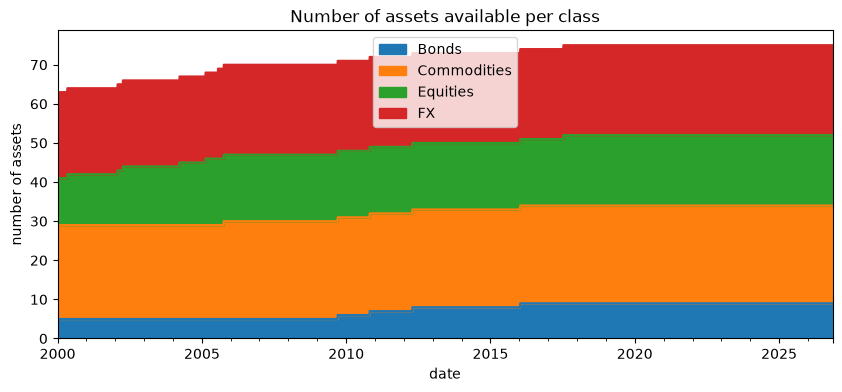

In [7]:
# True where a price exists, then count per class for each day
counts = prices.notna().T.groupby(asset_class).sum().T

counts.plot.area(figsize=(10, 4), title="Number of assets available per class")
plt.ylabel("number of assets")
plt.show()

The universe grows from about 68 assets in 2000 to 75 today, because some contracts were launched later: OAT1 (2012), UXY1 (2016) or KAA1 (usable from 2010).

This matters for the method: each month the model ranks assets **against each other** (this is the "cross-sectional" in the title), using only the assets that have a price on that date. We never fill a missing history with invented data.

## Step 3: Daily returns and volatility

### Daily returns
- We use the pandas function `pct_change` to get the returns from one row to another (daily returns).
- `fill_method=None` is used as argument so that missing prices aren't filled before computing returns: with it, a missing price gives a missing return instead of inventing data.

In [8]:
# Return on day t = price_t / price_(t-1) - 1
returns = prices.pct_change(fill_method=None)
returns.tail()

,XM1 Comdty,CN1 Comdty,RX1 Comdty,G 1 Comdty,JB1 Comdty,UXY1 Comdty,KAA1 Comdty,OAT1 Comdty,IK1 Comdty,BO1 Comdty,...,CZKUSDCR Curncy,HUFUSDCR Curncy,IDRUSDCR Curncy,INRUSDCR Curncy,KRWUSDCR Curncy,MXNUSDCR Curncy,PLNUSDCR Curncy,SGDUSDCR Curncy,TWDUSDCR Curncy,ZARUSDCR Curncy
date,,,,,,,,,,,,,,,,,,,,,
2026-11-04,0.000053,0.004777,0.001632,0.008963,-0.002447,0.004487,0.003607,0.009484,0.006236,-0.026808,...,0.006021,0.009690,-0.000848,0.001227,0.003214,0.011586,0.009449,0.002415,-0.001437,0.012311
2026-11-05,0.000790,0.002462,0.003585,0.001615,0.005063,0.004755,0.006359,0.001642,0.001505,-0.020305,...,-0.003308,-0.006054,0.004674,0.001994,-0.011031,-0.007225,-0.003935,0.000533,-0.001834,-0.003837
2026-11-06,0.000263,0.001778,-0.000325,-0.000921,0.009210,-0.002008,0.001649,0.002003,0.000884,0.000321,...,-0.006835,-0.003517,-0.001520,0.006097,-0.005870,0.007630,-0.005386,-0.003838,0.003099,-0.003250
2026-11-09,-0.000211,0.001184,-0.001706,0.001845,-0.002730,-0.000144,0.000183,0.001454,0.001148,-0.003694,...,0.007244,0.010026,0.001520,-0.000033,0.016476,0.004415,0.008669,0.002800,-0.003960,0.009756
2026-11-10,0.000158,-0.003715,-0.000244,-0.004143,-0.001408,-0.008336,0.000823,0.000635,0.000441,-0.004836,...,-0.004356,-0.007964,0.001963,0.000000,-0.000935,-0.008279,-0.004851,-0.002055,-0.000030,-0.006499


**Holidays:** about 70% of assets show a zero return on 1 January. Bloomberg repeats the last price on days the market is closed. We keep these zeros: the next trading day's return contains the whole move, so total performance stays correct, and only volatility is very slightly underestimated. Removing all zero returns would also remove genuine "no change" days.

### Sanity check, the 5 biggest daily moves

In [9]:
returns.abs().stack().sort_values(ascending=False).head(5)

date                  
2022-03-07  LN1 Comdty    0.634603
2020-04-21  CL1 Comdty    0.433414
2003-02-24  NG1 Comdty    0.383137
2020-03-23  XB1 Comdty    0.319945
2026-01-30  SI1 Comdty    0.313720
dtype: float64

We get real events:
- **Nickel (LN1), +63% on 7 March 2022:** the famous nickel short squeeze on the London Metal Exchange.
- **WTI oil (CL1), −43% on 21 April 2020:** oil prices collapsed during COVID.
- **Natural gas (NG1) 2003, gasoline (XB1) March 2020, silver (SI1) January 2026.**

### Annual volatility per asset class

- `returns.std()` is the standard deviation of daily returns which gives us the daily volatility.
- then we annualise the daily volatility with a square root of time to get the annual volatility: daily vol × √252 (252 trading days per year). We use the square root because the variances of independent returns add up over time.

In [10]:
vol = returns.std() * np.sqrt(252)      # daily std -> yearly
vol.groupby(asset_class).median()

Bonds          0.058472
Commodities    0.288140
Equities       0.215876
FX             0.111774
dtype: float64

**Medians:** bonds about 6%, FX about 11%, equities about 22%, commodities about 29%.

In [11]:
vol.sort_values()

XM1 Comdty         0.009857
JB1 Comdty         0.029761
CNYUSDCR Curncy    0.029967
TWDUSDCR Curncy    0.040596
SGDUSDCR Curncy    0.049747
                     ...   
CO1 Comdty         0.361774
LN1 Comdty         0.368933
XB1 Comdty         0.382310
CL1 Comdty         0.405285
NG1 Comdty         0.541884
Length: 75, dtype: float64

The extremes: the Australian 10-year bond (XM1) moves about 1% per year, natural gas (NG1) about 54%, a gap of about 50x. Without correction, a portfolio holding the same amount of each asset would be driven almost only by energy commodities.

## Step 4: Volatility scaling

**The problem (seen at step 3):** natural gas moves about 50 times more than the Australian bond. If we put the same amount of money on each, the portfolio’s results would really just be the natural gas results.

**The paper’s fix (Poh et al.):** size each position so that every asset contributes the same risk. Each asset’s return is multiplied by: **target vol / the asset’s estimated vol**.

The paper uses a **target of 15% per year**. A calm asset gets a bigger position, a wild one a smaller one.

Two details that matter:

1. **How we estimate an asset’s vol.** The paper uses an exponentially weighted standard deviation over about **63 days** (one quarter of trading days). “Exponentially weighted” means recent days count more than old ones, so the estimate reacts quickly when markets get calmer or rougher.
2. **No peeking into the future.** On day t we decide the position using only data up to day t. That position then earns the return of day t+1. In code, that’s .shift(1): today’s return gets multiplied by yesterday’s vol estimate. If we forgot it, we’d be using information we couldn’t have had at the time. That’s called look-ahead bias, and it’s the classic way to fake a great backtest.

### Ex-ante volatility = volatility estimated using past data only

- `min_periods=63:` we don’t trust the estimate until we have 63 days of data, so the first 63 days stay empty.

In [12]:
# "Ex-ante" = estimated with past data only
ex_ante_vol = returns.ewm(span=63, min_periods=63).std() * np.sqrt(252)
ex_ante_vol.iloc[-1].sort_values()     # today's estimate for each asset

XM1 Comdty         0.007537
CNYUSDCR Curncy    0.014841
SGDUSDCR Curncy    0.030393
IDRUSDCR Curncy    0.042724
INRUSDCR Curncy    0.043354
                     ...   
CC1 Comdty         0.450156
HO1 Comdty         0.488384
CL1 Comdty         0.496480
CO1 Comdty         0.521660
QS1 Comdty         0.552364
Name: 2026-11-10 00:00:00, Length: 75, dtype: float64

### Scale the returns and check

In [13]:
TARGET_VOL = 0.15

# Yesterday's vol estimate sizes today's return (no look-ahead)
scaled_returns = returns * (TARGET_VOL / ex_ante_vol.shift(1))

realised = scaled_returns.std() * np.sqrt(252)
realised.sort_values()

EURUSDCR Curncy    0.153084
SEKUSDCR Curncy    0.153094
CN1 Comdty         0.153104
XM1 Comdty         0.153107
CADUSDCR Curncy    0.153177
                     ...   
LN1 Comdty         0.161190
TWDUSDCR Curncy    0.161891
INRUSDCR Curncy    0.162176
CHFUSDCR Curncy    0.172467
CNYUSDCR Curncy    0.174607
Length: 75, dtype: float64

- Almost every asset now has a realised volatility of 15.3 to 15.5%, from bonds to natural gas: the scaling works. Results land slightly above 15% because the estimate always lags a little behind sudden changes in volatility.
- **CNY:** before the fix, CNYUSDCR came out at about 70%. While the yuan was pegged (until July 2005) its estimated volatility was about 0.08%, so the formula took a position about 500 times the normal size, and any small move exploded. Lesson: **vol scaling breaks on an asset that does not trade freely**. Fix: the series starts after the peg (cleaning cell, step 1). It now lands at about 17.5%.
- **CHF** at about 17%: on 15 January 2015 the Swiss central bank suddenly removed its cap on the franc, which jumped about 20% in one day after a very calm period. No volatility estimate could anticipate that shock.

## Step 5: Momentum features

**The idea of the project:** at the end of each month, the model looks at a few numbers for each asset and ranks the assets from “best to buy” to “best to sell”. Those numbers are the features.

They’re all momentum signals. Momentum is the observation, documented across many markets, that assets which went up recently tend to keep going up for a while, and the same for down.

The paper (Poh et al.) uses 3 families of features:
1. **Raw returns** over the past 3, 6 and 12 months
2. **Normalised returns:** the same returns, divided by the asset’s volatility
3. **MACD indicators**, a smoother trend signal (step 6)

**Why normalise?** The model compares assets against each other. +10% in 3 months is huge for a bond and ordinary for natural gas. Dividing by volatility turns every return into “how many normal-sized moves was this?”, which is comparable across assets.

The formula, for a horizon of k days:

$$
\text{normalised return} = \frac{\text{return over } k \text{ days}}{\text{daily vol} \times \sqrt{k}}
$$

The √k is the same square-root-of-time rule from step 3, used here to turn a daily vol into a k-day vol.

### Build the features

In [14]:
HORIZONS = {"3m": 63, "6m": 126, "12m": 252}    # in trading days
daily_vol = ex_ante_vol / np.sqrt(252)          # back from yearly to daily

feats = {}
for name, k in HORIZONS.items():
    ret_k = prices / prices.shift(k) - 1                       # return over the past k days
    feats[f"ret_{name}"] = ret_k
    feats[f"norm_ret_{name}"] = ret_k / (daily_vol * np.sqrt(k))

list(feats.keys())

['ret_3m', 'norm_ret_3m', 'ret_6m', 'norm_ret_6m', 'ret_12m', 'norm_ret_12m']

- `prices / prices.shift(k) - 1` is today’s price compared with the price k days ago. That’s the return over that period.
- No look-ahead here: everything uses data up to and including day t. The position is only taken afterwards (the `.shift(1)` happens when we compute strategy returns).

## Step 6: MACD (Moving Average Convergence Divergence) features

**What MACD is:** take two moving averages of the price:

- a **fast** one that follows recent prices closely
- a **slow** one that reacts later

MACD is **fast − slow**.

- **Positive** means recent prices are above the longer-term average, so the asset is trending up.
- **Negative** means it’s trending down.

It’s a smoother momentum signal than raw returns. A raw 3-month return depends a lot on the single price 63 days ago, while a moving average uses the whole path.

**Paper’s version (Poh et al., taken from Baz et al.):** three pairs of speeds, (8, 24), (16, 48) and (32, 96). That’s a short, medium and long trend. Each MACD is then normalised in two steps:

1. **Divide by the standard deviation of the price over the last 63 days.** MACD is in price units (dollars for oil, points for the S&P), and this makes it unit-free, so assets become comparable.
2. **Divide by the standard deviation of that result over the last 252 days.** This makes it comparable over time, so a calm year and a crazy year are on the same scale.
3. **Lagged copies.** The paper also feeds the model the value of each MACD 1, 3, 6 and 12 months ago, so it can see whether a trend is building up or fading.
4. **Baz composite signal.** Baz et al. combine the 3 MACDs into one signal by passing each through a response function and summing:
$$
\phi(y) = \frac{y \, e^{-y^2/4}}{0.89}
$$
φ grows with the signal up to about |y| = 1.4, then shrinks back towards 0. So the composite bets most on moderate trends and less on extreme ones, which often reverse.

In total: 3 MACDs + 12 lagged copies + 1 composite = **16 MACD features**, as in the paper.

### Add the MACD features

In [15]:
MACD_PAIRS = [(8, 24), (16, 48), (32, 96)]                  # (fast, slow) speeds
LAGS = {"1m": 21, "3m": 63, "6m": 126, "12m": 252}          # in trading days

def phi(y):
    """Baz et al. response function."""
    return y * np.exp(-y**2 / 4) / 0.89

composite = 0
for S, L in MACD_PAIRS:
    macd = prices.ewm(alpha=1/S).mean() - prices.ewm(alpha=1/L).mean()
    q = macd / prices.rolling(63).std()        # step 1: remove price units
    y = q / q.rolling(252).std()               # step 2: comparable over time
    feats[f"macd_{S}_{L}"] = y
    for lag_name, d in LAGS.items():
        feats[f"macd_{S}_{L}_lag{lag_name}"] = y.shift(d)   # value d days ago
    composite = composite + phi(y)

feats["macd_composite"] = composite
len(feats)    # 22

22

**About `alpha=1/S`:** the paper defines each moving average by its half-life, HL = log(0.5) / log(1 − 1/S). That is exactly an exponential average where each new day gets weight 1/S, so `alpha=1/S` is the same formula written more simply.

**About `y.shift(d)`:** it moves the series d days forward in time, so on date t the lagged feature holds the value from t − d. It only looks backwards, so there is no look-ahead.

## Step 7: Assemble the feature table

### Reshape to “one row per (date, asset)”

In [16]:
features = pd.concat({name: df.stack() for name, df in feats.items()}, axis=1)
features.index.names = ["date", "asset"]
features = features.dropna()        # keep rows where every feature exists
features.tail()

ret_3m  norm_ret_3m    ret_6m  norm_ret_6m  \
date       asset                                                           
2026-11-10 MXNUSDCR Curncy -0.083367    -1.495167 -0.063717    -0.808046   
           PLNUSDCR Curncy -0.048213    -1.257903 -0.073570    -1.357285   
           SGDUSDCR Curncy -0.006287    -0.413686 -0.013566    -0.631255   
           TWDUSDCR Curncy -0.028916    -1.284028 -0.052296    -1.642077   
           ZARUSDCR Curncy -0.012007    -0.253278  0.018850     0.281158   

                             ret_12m  norm_ret_12m  macd_8_24  \
date       asset                                                
2026-11-10 MXNUSDCR Curncy  0.017404      0.156068  -0.945681   
           PLNUSDCR Curncy -0.061211     -0.798520  -0.932145   
           SGDUSDCR Curncy -0.002927     -0.096296  -0.850371   
           TWDUSDCR Curncy -0.065791     -1.460741  -1.977345   
           ZARUSDCR Curncy  0.083146      0.876917  -0.333137   

                            macd_8_24_lag1m  macd_8_24_lag3m  macd_8_24_lag6m  \
date       asset                                                                
2026-11-10 MXNUSDCR Curncy        -1.927255         2.711187         1.650190   
           PLNUSDCR Curncy        -1.911563        -0.188566         0.250715   
           SGDUSDCR Curncy        -0.844748         0.179210        -0.288119   
           TWDUSDCR Curncy        -0.325494        -1.407282         0.312469   
           ZARUSDCR Curncy        -0.911515         1.489585         0.286528   

                            ...  macd_16_48_lag1m  macd_16_48_lag3m  \
date       asset            ...                                       
2026-11-10 MXNUSDCR Curncy  ...         -0.921228          2.628607   
           PLNUSDCR Curncy  ...         -1.529928         -0.892097   
           SGDUSDCR Curncy  ...         -0.667548         -1.355794   
           TWDUSDCR Curncy  ...         -0.667474         -1.549391   
           ZARUSDCR Curncy  ...          0.251535          1.526843   

                            macd_16_48_lag6m  macd_16_48_lag12m  macd_32_96  \
date       asset                                                              
2026-11-10 MXNUSDCR Curncy          2.115686           1.396649   -0.181844   
           PLNUSDCR Curncy          0.082800           0.552811   -0.820992   
           SGDUSDCR Curncy         -0.232527          -1.018946   -1.833441   
           TWDUSDCR Curncy         -0.519654          -1.084394   -1.748619   
           ZARUSDCR Curncy          0.601979           1.873903    1.728071   

                            macd_32_96_lag1m  macd_32_96_lag3m  \
date       asset                                                 
2026-11-10 MXNUSDCR Curncy          0.528549          3.352525   
           PLNUSDCR Curncy         -0.699863         -0.482321   
           SGDUSDCR Curncy         -1.463882         -1.582924   
           TWDUSDCR Curncy         -1.624932         -1.096870   
           ZARUSDCR Curncy          2.225151          3.998798   

                            macd_32_96_lag6m  macd_32_96_lag12m  \
date       asset                                                  
2026-11-10 MXNUSDCR Curncy          2.147614           1.499903   
           PLNUSDCR Curncy          0.463048           1.992130   
           SGDUSDCR Curncy          0.003024          -0.230908   
           TWDUSDCR Curncy         -1.204684          -0.158786   
           ZARUSDCR Curncy          1.919655           2.803060   

                            macd_composite  
date       asset                            
2026-11-10 MXNUSDCR Curncy       -1.948730  
           PLNUSDCR Curncy       -2.579450  
           SGDUSDCR Curncy       -2.629062  
           TWDUSDCR Curncy       -2.665770  
           ZARUSDCR Curncy        0.392093  

[5 rows x 22 columns]

**Why change the shape:** until now each table was dates × assets. A ranking model wants one row per (date, asset) pair, with one column per feature. That’s how it learns to “rank all assets on a given date”.

- `.stack()` turns the asset columns into rows.
- `pd.concat(..., axis=1)` puts the 22 features side by side.

Result: about 459,000 rows × 22 features. The first date is 04/03/2002: the 12-month-lagged MACD needs 63 + 252 + 252 days of history, and `dropna()` removes earlier rows. On that first date 63 assets are available, 75 today.

### Look at today’s ranking

In [17]:
features.loc["2026-11-10"].sort_values("norm_ret_12m", ascending=False).head(5)

,ret_3m,norm_ret_3m,ret_6m,norm_ret_6m,ret_12m,norm_ret_12m,macd_8_24,macd_8_24_lag1m,macd_8_24_lag3m,macd_8_24_lag6m,...,macd_16_48_lag1m,macd_16_48_lag3m,macd_16_48_lag6m,macd_16_48_lag12m,macd_32_96,macd_32_96_lag1m,macd_32_96_lag3m,macd_32_96_lag6m,macd_32_96_lag12m,macd_composite
asset,,,,,,,,,,,,,,,,,,,,,
HO1 Comdty,0.053903,0.220741,0.184256,0.533552,1.493331,3.057700,0.116313,1.284078,1.336695,0.906379,...,2.820016,2.079642,2.758894,1.587778,3.362538,2.742338,2.137468,3.163474,0.940377,0.914320
QS1 Comdty,0.099101,0.358826,0.234697,0.600894,1.576471,2.854044,0.431560,1.145056,1.370517,0.779143,...,2.840931,1.866180,1.981368,1.505279,4.334028,3.419119,2.453603,2.048888,1.196063,0.921779
CNYUSDCR Curncy,0.001877,0.252940,0.002833,0.269922,0.032974,2.221837,1.673611,0.350944,1.075363,1.824164,...,3.906825,3.160940,3.745164,0.901383,3.904130,3.898798,3.168999,2.635462,0.968111,1.030856
CO1 Comdty,0.156863,0.601398,-0.061925,-0.167877,0.979691,1.878025,0.499076,1.440310,0.238978,1.237232,...,1.660561,0.240736,2.046604,-0.745691,1.895413,1.698180,1.086723,2.484162,-0.866995,2.347067
XB1 Comdty,0.015471,0.070214,-0.048799,-0.156603,0.817604,1.855328,-0.864885,1.439043,0.846646,1.649313,...,2.690681,2.294544,2.547808,1.537429,2.770792,2.343232,2.870585,2.265059,0.975858,0.597984


The top of the 12-month normalised ranking is oil products (heating oil HO1, gasoil QS1). The yuan comes 3rd even though its raw 12-month return is only +3%: for an asset that moves about 1.5% per year, +3% is an exceptional move. This is normalisation at work.

Note also `macd_composite`: HO1 has a huge trend but a composite of about 0.9, not more, because φ deliberately shrinks extreme signals.

### How related are the features?

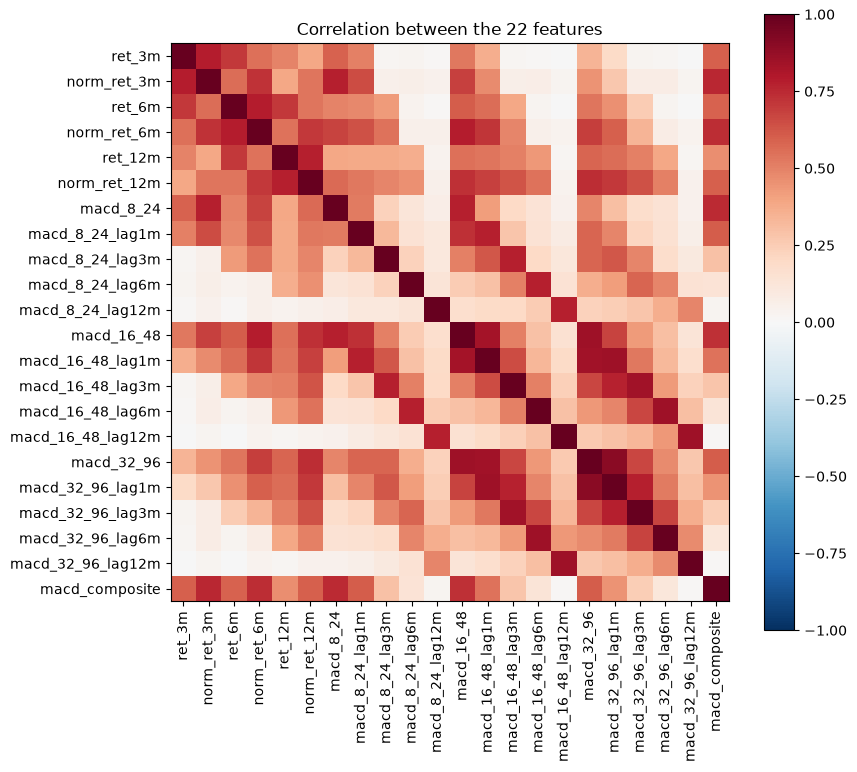

In [18]:
# features.corr().round(2)
corr = features.corr()
plt.figure(figsize=(9, 8))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.title("Correlation between the 22 features")
plt.show()

Most features are positively correlated because they all measure trend, at different speeds: the composite is about 0.75 correlated with norm_ret_3m and macd_8_24. Lagged copies decorrelate quickly: macd_16_48 vs its own value 1 month ago is about 0.83, 12 months ago only about 0.15, so the lags bring new information.

Strong correlation between inputs is not a problem for ranking accuracy, but it makes feature importances less stable, which we should keep in mind when interpreting the model.

## Step 8: Keep only month-end dates

The paper rebalances once a month: at the end of each month, assets are ranked and the portfolio is held for the next month. We keep only the last available date of each month. Daily rows would repeat almost the same features 21 times per month without adding information.

November 2026 is dropped: the data stops on 10/11, which is not a real month-end.

In [20]:
dates = features.index.get_level_values("date")

# Last available date in each calendar month
month_ends = dates.to_series().groupby(dates.to_period("M")).max()

# Drop the current, incomplete month (data stops on 10/11/2026)
month_ends = month_ends[month_ends.index < "2026-11"]

monthly = features[dates.isin(month_ends)]
monthly.shape

(21105, 22)

- `dates.to_period("M")` turns each date into its month (2002-03, 2002-04, ...), so `groupby(...).max()` gives the last date of each month.
- `isin` keeps the rows whose date is one of those month-ends, for all assets at once.

In [21]:
monthly.index.get_level_values("date").unique()[-5:], monthly.groupby(level="date").size().describe()

(DatetimeIndex(['2026-06-30', '2026-07-31', '2026-08-31', '2026-09-30',
                '2026-10-30'],
               dtype='datetime64[us]', name='date', freq=None),
 count    296.000000
 mean      71.300676
 std        3.639817
 min       63.000000
 25%       70.000000
 50%       73.000000
 75%       75.000000
 max       75.000000
 dtype: float64)

We get:
- 296 month-ends (March 2002 to October 2026)
- 21,105 rows (296 dates × about 71 assets on average)
- between 63 and 75 assets per date
- the last dates are 30/06, 31/07, 31/08, 30/09 and 30/10/2026: the last weekday of each month

## Step 9: Target, next month's vol-normalised return

For each month-end t and each asset, the target is the return over the next 21 trading days, divided by the asset's volatility at t (scaled to 21 days). Dividing by volatility makes assets comparable: otherwise the most volatile commodities would always sit at the top and bottom of every ranking.

`shift(-21)` looks into the future. That is fine for the target, which is what the model must learn to predict, but it must never be used as a feature.

In [24]:
H = 21    # holding period in trading days (about 1 month)

fwd_ret = prices.shift(-H) / prices - 1                 # return from t to t+21
target = fwd_ret / (daily_vol * np.sqrt(H))             # vol known at t

# Name the level "asset" so the join matches on (date, asset), not just date
target_long = target.rename_axis(columns="asset").stack().rename("target")

data = monthly.join(target_long, how="inner")
data = data.dropna(subset=["target"])
data.shape, data.index.get_level_values("date").max()

((21030, 23), Timestamp('2026-09-30 00:00:00'))

- `target.stack()` puts the target in the same (date, asset) shape as monthly, and join adds it as a 23rd column.
- `how="inner"` keeps only the rows that exist in both tables, so only month-ends.
- `rename_axis(columns="asset")` gives the stacked level the same name as in `monthly`. Without it, pandas joins on `date` alone and pairs every asset's features with every other asset's target (we got 1.5M rows instead of about 21k).

In [25]:
data["target"].describe()

count    21030.000000
mean         0.085201
std          1.091663
min         -8.222460
25%         -0.588942
50%          0.109281
75%          0.756810
max          9.251010
Name: target, dtype: float64

## Step 10: Ranking labels (deciles)

LambdaMART learns to order assets on each date, so it needs integer relevance grades rather than raw returns. On each month-end, assets are split into 10 equal groups by their target: 0 = worst next month, 9 = best. This also limits the effect of extreme moves: an outlier is simply "top decile".

In [26]:
def to_deciles(s):
    # rank first so ties don't break qcut, then cut into 10 equal groups
    return pd.qcut(s.rank(method="first"), 10, labels=False)

data["label"] = data.groupby(level="date")["target"].transform(to_deciles)
data["label"].value_counts().sort_index()

label
0    2244
1    2038
2    2092
3    2071
4    2152
5    2024
6    2048
7    2115
8    2015
9    2231
Name: count, dtype: int64

- `groupby(level="date")` means each month is ranked on its own.
- `rank(method="first")` gives every asset a distinct rank, so `qcut` never fails on equal values.
- `transform` returns one value per row, aligned with `data`.

## Step 11: Backtest engine and baselines

Every method (baselines now, LTR models later) goes through the same rule: at each month-end, score the assets, go long the top decile and short the bottom decile, equal weight, each position scaled to 15% volatility, held one month. Only the score changes, so comparisons are fair.

A position scaled to 15% vol earns r × 0.15 / σ_annual, which equals 0.15 × √(21/252) × target. The vol-scaled return is therefore already in `data`.

Baselines from the paper:
- **Random:** random scores, shows what no skill looks like (Sharpe ≈ 0)
- **Jegadeesh-Titman:** raw 12-month return
- **Baz:** MACD composite

In [27]:
# Next-month return of a position scaled to 15% annual vol
data["scaled_fwd"] = TARGET_VOL * np.sqrt(H / 252) * data["target"]

def long_short(score):
    """Monthly return: mean of top decile minus mean of bottom decile, ranked by score."""
    dec = score.groupby(level="date").transform(to_deciles)
    long = data["scaled_fwd"][dec == 9].groupby(level="date").mean()
    short = data["scaled_fwd"][dec == 0].groupby(level="date").mean()
    return long - short

def stats(r):
    ann_ret = r.mean() * 12
    ann_vol = r.std() * np.sqrt(12)
    return pd.Series({"ann. return": ann_ret, "ann. vol": ann_vol, "Sharpe": ann_ret / ann_vol})

In [28]:
rng = np.random.default_rng(0)       # fixed seed so the result is reproducible

scores = {
    "Random": pd.Series(rng.random(len(data)), index=data.index),
    "JT (12m return)": data["ret_12m"],
    "Baz (MACD)": data["macd_composite"],
}

strat = pd.DataFrame({name: long_short(s) for name, s in scores.items()})
strat.apply(stats).T.round(3)

,ann. return,ann. vol,Sharpe
Random,-0.009,0.077,-0.112
JT (12m return),0.077,0.119,0.647
Baz (MACD),0.103,0.129,0.799


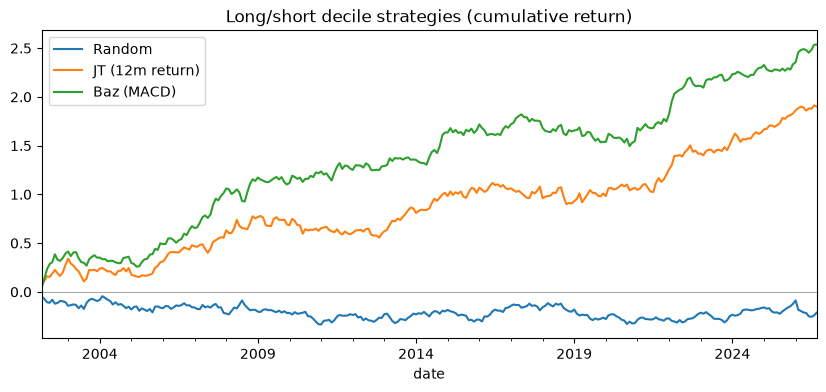

In [29]:
strat.cumsum().plot(figsize=(10, 4), title="Long/short decile strategies (cumulative return)")
plt.axhline(0, color="grey", lw=0.5)
plt.show()